In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df=pd.read_csv(r"C:\Users\bhatk\Downloads\archive (1)\StudentsPerformance.csv")
print("Data loaded successfully !!!")

Data loaded successfully !!!


In [4]:
print("Original Dataset")
print(df.head())

Original Dataset
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [5]:
print("\nShape of Dataset:")
print(df.shape)


Shape of Dataset:
(1000, 8)


In [6]:
print("\n Column names:")
print(df.columns)


 Column names:
Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')


In [7]:
print("\n Last 5 rows of Datasets:")
print(df.tail())


 Last 5 rows of Datasets:
     gender race/ethnicity parental level of education         lunch  \
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
995               completed          88             99             95  
996                    none          62             55             55  
997               completed          59             71             65  
998               completed          68             78             77  
999                    none          77             86             86  


In [8]:
data=df["math score"].dropna()
print("\n Number of math score values:",len(data))


 Number of math score values: 1000


In [9]:
Q1=data.quantile(0.25)
Q3=data.quantile(0.75)
IQR=Q3-Q1
lower_limit=Q1-1.5*IQR
upper_limit=Q3+1.5*IQR
print("\nIQR METHOD")
print("Q1:",Q1)
print("\nQ3:",Q3)
print("IQR:",IQR)
print("\nLower Limit:",lower_limit)
print("\nUpper Limit:",upper_limit)


IQR METHOD
Q1: 57.0

Q3: 77.0
IQR: 20.0

Lower Limit: 27.0

Upper Limit: 107.0


In [10]:
iqr_outliers=df[
    (df["math score"]<lower_limit)
    |(df["math score"]>upper_limit)
]
print("Number of IQR outliers:",len(iqr_outliers))

Number of IQR outliers: 8


In [11]:
mean=data.mean()
std=data.std()
df["Z_score"]=(df['math score']-mean)/std
z_outliers=df[abs(df["Z_score"])>3]
print("\n Z-SCORE METHOD")
print("Mean:",mean)
print("\nStandard Deviation:",std)
print("\nNumber of Z-score outliers:",len(z_outliers))


 Z-SCORE METHOD
Mean: 66.089

Standard Deviation: 15.163080096009468

Number of Z-score outliers: 4


In [12]:
df["math_score_treated"]=df["math score"].clip(
    lower=lower_limit,
    upper=upper_limit)
print("Treatment method:Capping using IQR limits")

Treatment method:Capping using IQR limits


In [13]:
comparison=df[
    ['math score',"math_score_treated"]
]
print(comparison.head(20))

    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


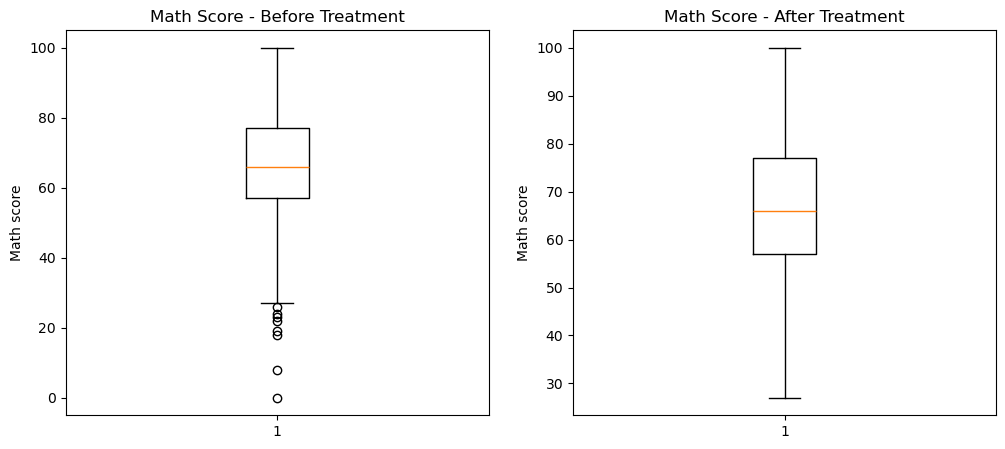

In [14]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math Score - Before Treatment")
plt.ylabel("Math score")
plt.subplot(1,2,2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - After Treatment")
plt.ylabel("Math score")
plt.show()